<a href="https://colab.research.google.com/github/Bhushan1024/Bhushan1024/blob/main/movielens_als_experiments.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Scalable Movie Recommendation Using Apache Spark ALS
Experiments for the research paper. Run the cells **top to bottom** (Runtime → Run all in Colab).

- **Experiment 1:** effect of rank (k = 5, 10, 20, 50) on RMSE, MovieLens 1M
- **Experiment 2:** training time and RMSE as data grows (100K → 1M → 10M), rank 10
- **Experiment 3:** effect of regularization λ (0.01, 0.1, 1.0) at the best rank from Experiment 1

Times are reported as **mean ± standard deviation (SD)** over 3 runs.

Every number you need for the paper's placeholders is printed in the final **Summary** cell.

## 1. Setup: install PySpark and print system details (for Section IV.B)

In [1]:
!pip install -q pyspark

import os, sys, platform, time, statistics, urllib.request, zipfile
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession, functions as F
from pyspark.ml.recommendation import ALS
from pyspark.ml.evaluation import RegressionEvaluator

spark = (SparkSession.builder
         .appName("MovieLens-ALS")
         .master("local[*]")                       # use all CPU cores
         .config("spark.driver.memory", "8g")      # lower to 4g if your machine has <8 GB RAM
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
spark.sparkContext.setCheckpointDir("/tmp/spark-checkpoints")

try:
    ram_gb = os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / 1e9
except (ValueError, AttributeError):
    ram_gb = float("nan")

print("Python  :", platform.python_version())
print("Spark   :", spark.version)
print("CPU cores:", os.cpu_count())
print(f"RAM     : {ram_gb:.1f} GB")

Python  : 3.13.18
Spark   : 4.0.5
CPU cores: 2
RAM     : 13.6 GB


## 2. Settings (same values as the paper's Methodology)

In [2]:
SEED        = 42      # fixed random seed -> reproducible split
TRAIN_FRAC  = 0.8     # 80% train / 20% test
MAX_ITER    = 10      # ALS iterations
REG_PARAM   = 0.1     # lambda (regularization)
RUNS        = 3       # repeat each timing and report the mean
RANKS       = [5, 10, 20, 50]          # Experiment 1
LAMBDAS     = [0.01, 0.1, 1.0]         # Experiment 3 (regularization strength)
SCALE_RANK  = 10                       # Experiment 2
DATASETS    = ["100K", "1M", "10M"]    # remove "10M" if it is too slow or runs out of memory

## 3. Download MovieLens datasets from GroupLens

In [3]:
SOURCES = {
    "100K": ("https://files.grouplens.org/datasets/movielens/ml-100k.zip", "ml-100k/u.data", "\t"),
    "1M":   ("https://files.grouplens.org/datasets/movielens/ml-1m.zip",   "ml-1m/ratings.dat", "::"),
    "10M":  ("https://files.grouplens.org/datasets/movielens/ml-10m.zip",  "ml-10M100K/ratings.dat", "::"),
}

def download(name):
    url, path, _ = SOURCES[name]
    if not os.path.exists(path):
        zip_name = url.split("/")[-1]
        print(f"Downloading {name} ...")
        urllib.request.urlretrieve(url, zip_name)
        with zipfile.ZipFile(zip_name) as z:
            z.extractall(".")
    return path

for name in set(DATASETS) | {"1M"}:
    download(name)
print("Done.")

Done.


## 4. Helper functions: load data, baseline, train and evaluate

In [4]:
def load_ratings(name):
    """Read a MovieLens ratings file into a DataFrame (userId, movieId, rating)."""
    _, path, sep = SOURCES[name]
    parts = F.split(F.col("value"), sep)
    return (spark.read.text(path)
            .select(parts.getItem(0).cast("int").alias("userId"),
                    parts.getItem(1).cast("int").alias("movieId"),
                    parts.getItem(2).cast("float").alias("rating")))

evaluator = RegressionEvaluator(metricName="rmse", labelCol="rating", predictionCol="prediction")

def split(df):
    train, test = df.randomSplit([TRAIN_FRAC, 1 - TRAIN_FRAC], seed=SEED)
    train.cache().count()   # load into memory now, so loading isn't counted as training time
    test.cache().count()
    return train, test

def baseline_rmse(train, test):
    """Predict every rating as the global mean of the training set."""
    mu = train.agg(F.mean("rating")).first()[0]
    return evaluator.evaluate(test.withColumn("prediction", F.lit(float(mu))))

def train_and_evaluate(train, test, rank, reg=REG_PARAM, runs=RUNS):
    """Train ALS `runs` times; return (mean time, SD of time, train RMSE, test RMSE)."""
    times = []
    for _ in range(runs):
        als = ALS(rank=rank, maxIter=MAX_ITER, regParam=reg,
                  userCol="userId", itemCol="movieId", ratingCol="rating",
                  coldStartStrategy="drop", seed=SEED, checkpointInterval=5)
        start = time.time()
        model = als.fit(train)              # ALS.fit runs all iterations here
        times.append(time.time() - start)
    train_rmse = evaluator.evaluate(model.transform(train))
    test_rmse  = evaluator.evaluate(model.transform(test))
    sd = statistics.stdev(times) if len(times) > 1 else 0.0
    return statistics.mean(times), sd, train_rmse, test_rmse

def fmt(mean, sd):
    return f"{mean:.2f} ± {sd:.2f}"

## 5. Experiment 1: effect of rank on MovieLens 1M → Table I

In [5]:
ratings_1m = load_ratings("1M")
train_1m, test_1m = split(ratings_1m)
base_1m = baseline_rmse(train_1m, test_1m)
train_and_evaluate(train_1m, test_1m, SCALE_RANK, runs=1)   # warm-up run: first Spark job is slower, so it is not reported

rows = [{"Model": "Global-mean baseline", "Rank (k)": "-", "Train RMSE": None,
         "Test RMSE": round(base_1m, 4), "Training time (s, mean ± SD)": "-"}]
for k in RANKS:
    t, sd, tr, te = train_and_evaluate(train_1m, test_1m, k)
    print(f"rank={k:>3}  train RMSE={tr:.4f}  test RMSE={te:.4f}  time={fmt(t, sd)}s")
    rows.append({"Model": "ALS", "Rank (k)": k, "Train RMSE": round(tr, 4),
                 "Test RMSE": round(te, 4), "Training time (s, mean ± SD)": fmt(t, sd)})

table1 = pd.DataFrame(rows)
table1.to_csv("table1_rank.csv", index=False)
table1

rank=  5  train RMSE=0.8474  test RMSE=0.8811  time=16.92 ± 3.50s
rank= 10  train RMSE=0.8194  test RMSE=0.8693  time=14.70 ± 0.18s
rank= 20  train RMSE=0.8027  test RMSE=0.8669  time=17.22 ± 0.17s
rank= 50  train RMSE=0.7898  test RMSE=0.8674  time=30.55 ± 0.47s


,Model,Rank (k),Train RMSE,Test RMSE,"Training time (s, mean ± SD)"
0,Global-mean baseline,-,NaN,1.1183,-
1,ALS,5,0.8474,0.8811,16.92 ± 3.50
2,ALS,10,0.8194,0.8693,14.70 ± 0.18
3,ALS,20,0.8027,0.8669,17.22 ± 0.17
4,ALS,50,0.7898,0.8674,30.55 ± 0.47


### Fig. 1: train vs test RMSE by rank

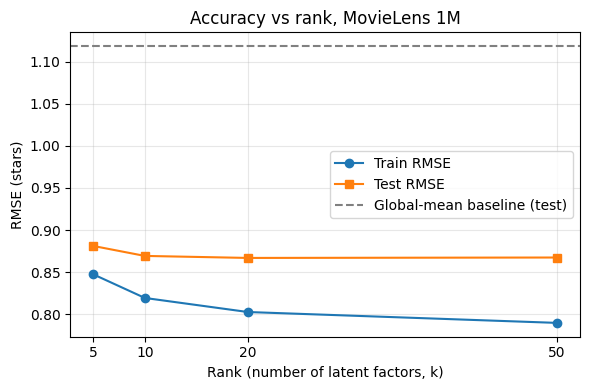

In [6]:
als_rows = table1[table1["Model"] == "ALS"]
plt.figure(figsize=(6, 4))
plt.plot(als_rows["Rank (k)"], als_rows["Train RMSE"], marker="o", label="Train RMSE")
plt.plot(als_rows["Rank (k)"], als_rows["Test RMSE"],  marker="s", label="Test RMSE")
plt.axhline(base_1m, linestyle="--", color="gray", label="Global-mean baseline (test)")
plt.xlabel("Rank (number of latent factors, k)")
plt.ylabel("RMSE (stars)")
plt.title("Accuracy vs rank, MovieLens 1M")
plt.xticks(RANKS)
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig("fig1_rank_vs_rmse.png", dpi=300)
plt.show()

## 5b. Experiment 3: effect of regularization λ on MovieLens 1M → Table III

In [7]:
best_rank = int(table1[table1["Model"] == "ALS"].sort_values("Test RMSE").iloc[0]["Rank (k)"])
print("Using best rank from Experiment 1:", best_rank)

rows = []
for lam in LAMBDAS:
    t, sd, tr, te = train_and_evaluate(train_1m, test_1m, best_rank, reg=lam)
    print(f"lambda={lam:<5} train RMSE={tr:.4f}  test RMSE={te:.4f}  time={fmt(t, sd)}s")
    rows.append({"λ (regParam)": lam, "Train RMSE": round(tr, 4), "Test RMSE": round(te, 4),
                 "Training time (s, mean ± SD)": fmt(t, sd)})

table3 = pd.DataFrame(rows)
table3.to_csv("table3_lambda.csv", index=False)
table3

Using best rank from Experiment 1: 20
lambda=0.01  train RMSE=0.6688  test RMSE=0.9425  time=19.51 ± 4.20s
lambda=0.1   train RMSE=0.8027  test RMSE=0.8669  time=19.68 ± 3.99s
lambda=1.0   train RMSE=1.3482  test RMSE=1.3537  time=18.94 ± 0.96s


,λ (regParam),Train RMSE,Test RMSE,"Training time (s, mean ± SD)"
0,0.01,0.6688,0.9425,19.51 ± 4.20
1,0.10,0.8027,0.8669,19.68 ± 3.99
2,1.00,1.3482,1.3537,18.94 ± 0.96


### Fig. 3: train vs test RMSE by λ

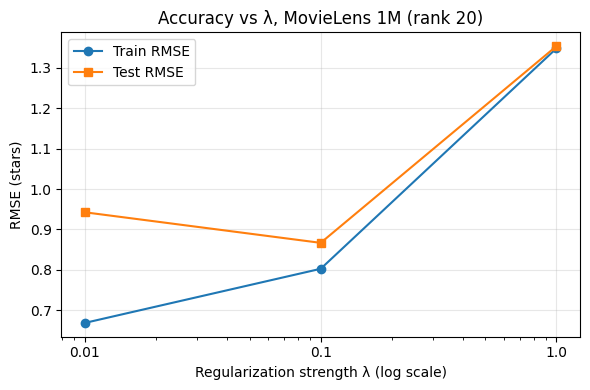

In [8]:
plt.figure(figsize=(6, 4))
plt.plot(table3["λ (regParam)"], table3["Train RMSE"], marker="o", label="Train RMSE")
plt.plot(table3["λ (regParam)"], table3["Test RMSE"],  marker="s", label="Test RMSE")
plt.xscale("log")
plt.xlabel("Regularization strength λ (log scale)")
plt.ylabel("RMSE (stars)")
plt.title(f"Accuracy vs λ, MovieLens 1M (rank {best_rank})")
plt.xticks(LAMBDAS, [str(l) for l in LAMBDAS])
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig("fig3_lambda_vs_rmse.png", dpi=300)
plt.show()

## 6. Experiment 2: scalability across dataset sizes → Table II

In [9]:
rows = []
for name in DATASETS:
    df = load_ratings(name)
    n = df.count()
    train, test = split(df)
    base = baseline_rmse(train, test)
    t, sd, _, te = train_and_evaluate(train, test, SCALE_RANK)
    print(f"{name:>4}: {n:>10,} ratings  time={fmt(t, sd)}s  test RMSE={te:.4f}  baseline={base:.4f}")
    rows.append({"Dataset": f"MovieLens {name}", "Ratings": n,
                 "Training time (s, mean)": round(t, 2), "SD (s)": round(sd, 2),
                 "Training time (s, mean ± SD)": fmt(t, sd),
                 "Test RMSE": round(te, 4), "Baseline RMSE": round(base, 4)})
    train.unpersist(); test.unpersist()

table2 = pd.DataFrame(rows)
table2.to_csv("table2_scalability.csv", index=False)
table2

100K:    100,000 ratings  time=5.34 ± 1.17s  test RMSE=0.9197  baseline=1.1285
  1M:  1,000,209 ratings  time=14.44 ± 0.33s  test RMSE=0.8693  baseline=1.1183
 10M: 10,000,054 ratings  time=106.27 ± 2.26s  test RMSE=0.8177  baseline=1.0615


,Dataset,Ratings,"Training time (s, mean)",SD (s),"Training time (s, mean ± SD)",Test RMSE,Baseline RMSE
0,MovieLens 100K,100000,5.34,1.17,5.34 ± 1.17,0.9197,1.1285
1,MovieLens 1M,1000209,14.44,0.33,14.44 ± 0.33,0.8693,1.1183
2,MovieLens 10M,10000054,106.27,2.26,106.27 ± 2.26,0.8177,1.0615


### Fig. 2: training time vs number of ratings

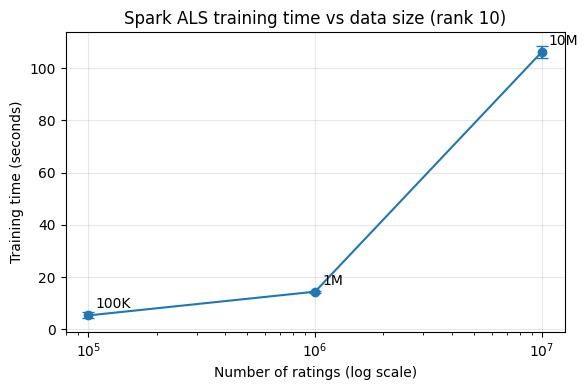

In [10]:
plt.figure(figsize=(6, 4))
plt.errorbar(table2["Ratings"], table2["Training time (s, mean)"], yerr=table2["SD (s)"], marker="o", capsize=4)
for _, r in table2.iterrows():
    plt.annotate(r["Dataset"].replace("MovieLens ", ""),
                 (r["Ratings"], r["Training time (s, mean)"]),
                 textcoords="offset points", xytext=(5, 5))
plt.xscale("log")
plt.xlabel("Number of ratings (log scale)")
plt.ylabel("Training time (seconds)")
plt.title(f"Spark ALS training time vs data size (rank {SCALE_RANK})")
plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig("fig2_time_vs_size.png", dpi=300)
plt.show()

## 7. Summary: every number for the paper's placeholders

In [11]:
best = als_rows.loc[als_rows["Test RMSE"].idxmin()]
improvement = (base_1m - best["Test RMSE"]) / base_1m * 100
t_first = table2["Training time (s, mean)"].iloc[0]
t_last  = table2["Training time (s, mean)"].iloc[-1]

print("=== Paste these into the paper ===")
print(f"Best test RMSE          : {best['Test RMSE']:.3f}  (rank {best['Rank (k)']})")
print(f"Baseline test RMSE (1M) : {base_1m:.3f}")
print(f"Improvement over baseline: {improvement:.1f}%")
best_l = table3.loc[table3["Test RMSE"].idxmin()]
print(f"Best lambda              : {best_l['λ (regParam)']}  (test RMSE {best_l['Test RMSE']:.3f}, rank {best_rank})")
print(f"Training time {table2['Dataset'].iloc[0]} : {table2['Training time (s, mean ± SD)'].iloc[0]} s")
print(f"Training time {table2['Dataset'].iloc[-1]} : {table2['Training time (s, mean ± SD)'].iloc[-1]} s")
print(f"Time growth factor       : {t_last / t_first:.1f}x  for "
      f"{table2['Ratings'].iloc[-1] / table2['Ratings'].iloc[0]:.0f}x more ratings")
print("\nTest RMSE by dataset:", dict(zip(table2["Dataset"], table2["Test RMSE"])))
print("\nFiles saved: table1_rank.csv, table2_scalability.csv, table3_lambda.csv, fig1_rank_vs_rmse.png, fig2_time_vs_size.png, fig3_lambda_vs_rmse.png")

=== Paste these into the paper ===
Best test RMSE          : 0.867  (rank 20)
Baseline test RMSE (1M) : 1.118
Improvement over baseline: 22.5%
Best lambda              : 0.1  (test RMSE 0.867, rank 20)
Training time MovieLens 100K : 5.34 ± 1.17 s
Training time MovieLens 10M : 106.27 ± 2.26 s
Time growth factor       : 19.9x  for 100x more ratings

Test RMSE by dataset: {'MovieLens 100K': 0.9197, 'MovieLens 1M': 0.8693, 'MovieLens 10M': 0.8177}

Files saved: table1_rank.csv, table2_scalability.csv, table3_lambda.csv, fig1_rank_vs_rmse.png, fig2_time_vs_size.png, fig3_lambda_vs_rmse.png
